# 04 Advisory generation: does verification make the advisory safer?

Until now the pipeline stops at verified claims and retrieved guidance. This notebook writes the advisory and tests the project's main idea: **an advisory built only from claims the satellite evidence supports should contain fewer wrong damage statements than one built from every claim the captioner made.**

Each tile is run under four conditions. Only the input differs. The prompt, the model and the settings are the same.

| condition | damage statements given to the model | guidance passages |
| --- | --- | --- |
| `A_no_retrieval` | all claims from the caption | none |
| `B_all_claims` | all claims from the caption | retrieved from all claims |
| `C_gated_labels` | only claims supported by label evidence | retrieved from those claims |
| `D_gated_predicted` | only claims supported by predicted evidence | retrieved from those claims |

**How to read C and D.** Statements are always scored against the label evidence (ground truth). C is gated by the same labels, so it can contain no wrong statement unless the model changes one; it shows the ceiling and how faithfully the model copies its input. D is gated by the vision model's predicted evidence and is the realistic test. Gate 2 showed that most quantity claims are contradicted, and the smoke run of this notebook found only 4 of 112 captioned claims supported by the labels and none by the predicted evidence. **Two checker versions.** Checker v2 treats a claim as not verifiable when its quantity word cannot occur with the cell's number of buildings ("few" needs at least 11 buildings, "some" at least 4, "many" at least 2); v1 called those claims contradicted. Supported verdicts are identical, so the gates for C and D do not change. Every table below is scored with v2 and with v1, which gives the same advisories two error rates. The v2 rule was added after Gate 2, so report v1 as well. So expect C to keep a handful of statements and D almost none. That is the result, not a bug: `no_statements` counts the advisories left with nothing to state, and the comparison between B and C or D is then mainly about how much wrong information the gate stops.

**What the model must produce.** A `SITUATION` block that copies the damage statements in the checker's line format (`r1c1: few of the buildings show minor damage.`), then an `ADVICE` block of short bullets, each ending with a passage tag such as `[P2]`. The situation block is in English for both languages so the checker can read it; only the advice is in Arabic.

**Measures** (all computed by code, no model judging another model)
1. Damage-statement error rate: the checker run on the generated situation block, against label evidence. Also statements that were invented (not in the input) or dropped.
2. Citation validity: share of bullets with a citation, and share of citations that point to a passage that was not given.
3. Two human rating sheets are written at the end: passage support of the advice (English and Arabic) and a blind Arabic comparison of the two models.

**Models.** `Qwen3-8B` (4-bit, non-thinking mode, greedy decoding) for everything. `Falcon-H1-Arabic` 7B only for about 10 Arabic advisories under condition B (the comparison is about the advice, not the gate), after a smoke test. If Falcon does not load, that part is skipped and the rest is unaffected. Only one model is on the GPU at a time.

**Run it.** Runtime > Change runtime type > a GPU (T4 is enough), then Run all. It saves after every advisory and skips finished ones, so if Colab disconnects, run all again. Expect roughly 1 to 1.5 hours on a T4, plus about 10 minutes the first time for the two model downloads (about 16 GB each). Set `SMOKE = True` first for a 3-tile check of about 5 minutes.

**Guidance corpus.** If `passages.csv` from notebook 03 exists, it is used. If not, 17 short **demo** passages written for this test are used and every output is marked `corpus = demo`. Demo runs test the code and the damage-statement and citation measures. They say nothing about passage support, and no figure from them goes in the report.

In [1]:
BRANCH = "main"

import os, subprocess, sys

REPO_DIR = "/content/FloodVerify"
if "google.colab" in sys.modules:
    if not os.path.exists(REPO_DIR):
        subprocess.run(["git", "clone", "https://github.com/aaarrvind/FloodVerify.git", REPO_DIR], check=True)
    subprocess.run(["git", "-C", REPO_DIR, "fetch", "origin"], check=True)
    subprocess.run(["git", "-C", REPO_DIR, "checkout", BRANCH], check=True)
    subprocess.run(["git", "-C", REPO_DIR, "pull"], check=True)
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "-U", "transformers>=4.53", "accelerate",
                    "bitsandbytes", "sentence-transformers", "pypdf", "pandas", "matplotlib"], check=True)
    REPO = REPO_DIR
else:
    REPO = os.path.abspath("../..")
sys.path.insert(0, os.path.join(REPO, "src"))
print("repo:", REPO)

repo: /content/FloodVerify


In [2]:
from google.colab import drive
drive.mount("/content/drive")

PROJECT = "/content/drive/MyDrive/MAAI 902 X 901 PROJECT"
ROOT = f"{PROJECT}/xbd"
CAPTIONS_FILE = f"{ROOT}/processed/captions/qwen3vl4b_cells_50.json"      # {tile_id: {cell_id: caption line}}
LABELS_DIR = f"{ROOT}/processed/evidence_labels"                          # ground truth, from xBD labels
PRED_DIR = f"{PROJECT}/evidence_predicted/m1_siamese_unet_ce_s0"          # vision team, read only
GUIDANCE_DIR = f"{PROJECT}/guidance"                                      # notebook 03 output
PASSAGES_CSV = f"{GUIDANCE_DIR}/passages.csv"
FORCE_DEMO = False          # True: use the 17 demo passages even if passages.csv exists (to re-score earlier demo runs)
EMB_FILE = f"{GUIDANCE_DIR}/passages_bge_m3.npy"
OUT = f"{PROJECT}/advisory_generation"                                    # our own folder
os.makedirs(OUT, exist_ok=True)
RUNS_FILE = f"{OUT}/advisories.jsonl"

QWEN_ID = "Qwen/Qwen3-8B"
FALCON_IDS = ["tiiuae/Falcon-H1-Arabic-7B-Instruct", "tiiuae/Falcon-H1-Arabic-7B"]   # tried in this order
EMBED_MODEL = "BAAI/bge-m3"
TOP_K = 3
N_TILES = 50            # tiles for the English experiment (all captioned tiles with a claim; there are about 50)
N_AR_TILES = 10         # tiles for the Arabic comparison
MAX_NEW_TOKENS = 350
SEED = 42
SMOKE = False           # True: 3 tiles, 2 Arabic tiles
USE_FALCON = True
if SMOKE:
    N_TILES, N_AR_TILES = 3, 2

CONDITIONS = {
    "A_no_retrieval":    {"claims": "all",       "evidence": None,        "retrieve": False},
    "B_all_claims":      {"claims": "all",       "evidence": None,        "retrieve": True},
    "C_gated_labels":    {"claims": "supported", "evidence": "labels",    "retrieve": True},
    "D_gated_predicted": {"claims": "supported", "evidence": "predicted", "retrieve": True},
}
AR_CONDITIONS = ["B_all_claims"]      # the Arabic comparison is about the advice, so it uses tiles that always have input

import torch
print("GPU:", torch.cuda.get_device_name(0) if torch.cuda.is_available() else "none")
assert torch.cuda.is_available(), "No GPU. Runtime > Change runtime type > T4 GPU, then run all again."

Mounted at /content/drive
GPU: Tesla T4


## 1. Tiles, claims and verdicts

Each captioned tile gives a list of claims (`extract_claims` from the repo). Every claim is checked twice with the repo's checker: against the label evidence (ground truth) and against the predicted evidence. The input of each condition is then a filter over these claims. The functions only read files; nothing is written back to the evidence folders.

In [3]:
import json, re, time, random, hashlib, gc
from pathlib import Path
import numpy as np
import pandas as pd
from floodsitrep.nlp.checker import verify_claims, bin_of, class_fraction, MIN_VALID
from floodsitrep.nlp.claims import extract_claims, report_from_cells, CELL_LINE
from floodsitrep.nlp.schema import Claim


def read_evidence(tile_id, folder):
    """Evidence dict for one tile, or None when the file is missing."""
    p = Path(folder) / f"{tile_id}.json"
    return json.loads(p.read_text()) if p.exists() else None


def caption_report(entry):
    """A caption entry ({cell: line} or already a report string) -> report text."""
    return entry if isinstance(entry, str) else report_from_cells(entry)


BIN_WORDS = ("none", "few", "some", "many", "most")


def reachable(quantity, total):
    """True when some building count out of `total` falls in the bin of the quantity word (checker v2 rule)."""
    return total > 0 and any(bin_of(k / total) == quantity for k in range(total + 1))


def cell_buildings(evidence, cell):
    """Buildings in the usable cells a claim refers to (the same selection the checker makes)."""
    cells = [c for c in evidence["cells"] if not cell or c["cell"] == cell]
    return sum(c["buildings"] for c in cells if c.get("valid_fraction", 1.0) >= MIN_VALID)


def both_versions(raw, quantity, total):
    """(v1, v2) verdicts from the installed checker's verdict, whichever checker version is installed.

    v2 abstains when the quantity word cannot occur with this many buildings. Supported verdicts are the same in both.
    """
    unreachable = quantity in BIN_WORDS and total > 0 and not reachable(quantity, total)
    v1 = "contradicted" if raw == "not_verifiable" and unreachable else raw
    v2 = "not_verifiable" if raw == "contradicted" and unreachable else raw
    return v1, v2


def claim_line(c):
    """Canonical checker line for one claim dict. Parsing it again gives the same claim."""
    cell, q, cls = c["cell"], c["quantity"], c["damage_class"]
    if q == "none":
        return f"{cell}: no damage."
    if cls == "destroyed":
        return f"{cell}: {q} of the buildings are destroyed."
    return f"{cell}: {q} of the buildings show {cls} damage."


def tile_claims(report, labels_ev, pred_ev):
    """Unique claims of one report as dicts, with a verdict against labels and (when available) predicted evidence."""
    claims = extract_claims(report)
    seen, uniq = set(), []
    for c in claims:
        key = (c.cell, c.quantity, c.damage_class)
        if key not in seen:
            seen.add(key)
            uniq.append(c)
    lab = verify_claims(uniq, labels_ev)
    pre = verify_claims(uniq, pred_ev) if pred_ev is not None else [None] * len(uniq)
    rows = []
    for c, a, b in zip(uniq, lab, pre):
        v1, v2 = both_versions(a.verdict, c.quantity, cell_buildings(labels_ev, c.cell))
        rows.append({"cell": c.cell, "quantity": c.quantity, "damage_class": c.damage_class,
                     "verdict_labels": a.verdict, "verdict_labels_v1": v1, "verdict_labels_v2": v2,
                     "verdict_predicted": b.verdict if b is not None else None})
    return sorted(rows, key=lambda r: (r["cell"], r["damage_class"], r["quantity"]))


def build_tile_info(caps, labels_dir, pred_dir):
    """{tile_id: {'claims': [...], 'has_predicted': bool}} for every captioned tile that has label evidence."""
    info = {}
    for tid, entry in caps.items():
        lab = read_evidence(tid, labels_dir)
        if lab is None:
            continue
        pre = read_evidence(tid, pred_dir)
        info[tid] = {"claims": tile_claims(caption_report(entry), lab, pre), "has_predicted": pre is not None}
    return info


def pick_tiles(info, n, seed=SEED, need_supported=False):
    """n tile ids with at least one claim, seeded random order, tiles with a predicted evidence file first.

    need_supported keeps only tiles with a claim supported by the label evidence.
    """
    ids = sorted(t for t, v in info.items() if v["claims"]
                 and (not need_supported or any(c["verdict_labels"] == "supported" for c in v["claims"])))
    random.Random(seed).shuffle(ids)
    ids.sort(key=lambda t: not info[t]["has_predicted"])
    return ids[:n]


caps = json.load(open(CAPTIONS_FILE))
tile_info = build_tile_info(caps, LABELS_DIR, PRED_DIR)
print(len(caps), "tiles captioned;", len(tile_info), "with label evidence;",
      sum(v["has_predicted"] for v in tile_info.values()), "also with predicted evidence")

/usr/local/lib/python3.13/dist-packages/pandas/core/arrays/masked.py:63: UserWarning: Pandas requires version '1.5.0' or newer of 'bottleneck' (version '1.4.2' currently installed).
  from pandas.core import (


50 tiles captioned; 50 with label evidence; 20 also with predicted evidence


In [4]:
def claim_overview(info):
    """Claim counts by verdict (labels and predicted), over all tiles with claims."""
    rows = [{"tile": t, **c} for t, v in info.items() for c in v["claims"]]
    df = pd.DataFrame(rows)
    out = df.groupby("verdict_labels_v1").size().rename("labels_checker_v1").to_frame()
    for name, col in (("labels_checker_v2", "verdict_labels_v2"),
                      ("predicted", df["verdict_predicted"].fillna("no predicted file"))):
        out = out.join(df.groupby(col).size().rename(name), how="outer")
    return out.fillna(0).astype(int)


print(claim_overview(tile_info))
en_tiles = pick_tiles(tile_info, N_TILES)
ar_tiles = en_tiles[:N_AR_TILES]
print(len(en_tiles), "English tiles;", len(ar_tiles), "Arabic tiles;",
      sum(tile_info[t]["has_predicted"] for t in en_tiles), "English tiles have predicted evidence (needed for condition D)")
print("English tiles with at least one supported claim (labels):",
      sum(any(c["verdict_labels"] == "supported" for c in tile_info[t]["claims"]) for t in en_tiles))
print("English tiles with at least one supported claim (predicted):",
      sum(any(c["verdict_predicted"] == "supported" for c in tile_info[t]["claims"]) for t in en_tiles))

                   labels_checker_v1  labels_checker_v2  predicted
verdict_labels_v1                                                 
contradicted                      92                 22         32
no predicted file                  0                  0         73
not_verifiable                    16                 86          7
supported                          4                  4          0
29 English tiles; 10 Arabic tiles; 10 English tiles have predicted evidence (needed for condition D)
English tiles with at least one supported claim (labels): 3
English tiles with at least one supported claim (predicted): 0


## 2. Guidance passages and retrieval

A stand-in retriever with the shape `retrieve(claims, lang, k)` agreed in notebook 03. When Member 5's version is in the repo, replace the cell below and keep the call. Passages come from notebook 03's `passages.csv`. If it does not exist, 17 demo passages are used (clearly marked). Retrieval is done once for every job and saved, then the embedding model is removed from the GPU before the generator loads.

In [5]:
DEMO_EN = [
    "Do not walk, swim or drive through flood water. It can hide holes, debris and fast-moving currents.",
    "Stay away from wadis and flood channels during heavy rain. Water levels can rise within minutes.",
    "Do not enter a building that was damaged by flood water until it has been checked by the authorities.",
    "If it is safe to do so, switch off the electricity at the main switch. Never touch electrical equipment while standing in water.",
    "Use bottled water or boil tap water until the authorities say the supply is safe to drink.",
    "Return home only when the authorities announce that it is safe to do so.",
    "Dry and clean the building as soon as possible to prevent mould. Wear gloves and a mask while cleaning.",
    "Report damaged buildings, roads and power lines to the emergency services. Call emergency numbers if lives are at risk.",
    "Move children, elderly people and people with disabilities to higher ground early. Prepare a bag with documents, medicine and water.",
]
DEMO_AR = [
    "لا تسر ولا تقد سيارتك في مياه الفيضان، فقد تخفي حفرا وحطاما وتيارا قويا.",
    "ابتعد عن الأودية ومجاري السيول أثناء الأمطار الغزيرة، فقد يرتفع منسوب المياه خلال دقائق.",
    "لا تدخل مبنى تضرر بمياه الفيضان قبل أن تفحصه الجهات المختصة.",
    "اقطع التيار الكهربائي من المفتاح الرئيسي إذا كان ذلك آمنا، ولا تلمس الأجهزة الكهربائية وأنت في الماء.",
    "استخدم مياه معبأة أو اغل مياه الشرب حتى تعلن الجهات المختصة أن مياه الشبكة آمنة.",
    "لا تعد إلى منزلك إلا بعد أن تعلن السلطات أن العودة آمنة.",
    "جفف المبنى ونظفه في أقرب وقت لمنع نمو العفن، وارتد قفازات وكمامة أثناء التنظيف.",
    "أبلغ الطوارئ عن المباني والطرق وخطوط الكهرباء المتضررة، واتصل برقم الطوارئ عند وجود خطر على الأرواح.",
]


def demo_passages():
    """17 short stand-in passages (9 English, 8 Arabic). Not official guidance: for testing the code only."""
    rows = []
    for lang, texts in (("en", DEMO_EN), ("ar", DEMO_AR)):
        for i, t in enumerate(texts):
            rows.append({"id": f"demo_{lang}_{i:02d}", "source_name": "DEMO stand-in (not official guidance)", "url": "",
                         "language": lang, "licence_note": "demo", "file": "demo", "text": t})
    return pd.DataFrame(rows)


def load_passages(path):
    """(passages, corpus_name). Uses notebook 03's passages.csv when it exists, else the demo set."""
    if os.path.exists(path) and not FORCE_DEMO:
        df = pd.read_csv(path, dtype=str).fillna("")
        df = df.rename(columns={"source": "source_name"})          # notebook 03 calls the column `source`
        for col in ("source_name", "url"):
            if col not in df.columns:
                df[col] = ""
        return df, "guidance"
    return demo_passages(), "demo"


passages, CORPUS = load_passages(PASSAGES_CSV)
print("corpus:", CORPUS, "|", len(passages), "passages |", passages["language"].value_counts().to_dict())
if CORPUS == "demo":
    print("WARNING: no passages.csv found, so the demo passages are used. Do not report passage-based results from this run.")

corpus: guidance | 130 passages | {'ar': 94, 'en': 36}


In [6]:
def load_embedder(name=EMBED_MODEL):
    """Sentence-transformers model on the GPU."""
    from sentence_transformers import SentenceTransformer
    return SentenceTransformer(name, device="cuda" if torch.cuda.is_available() else "cpu")


def passages_key(passages, model_name):
    """Fingerprint of the passages and the model, to know when saved vectors are stale."""
    return hashlib.sha1((model_name + "|" + "|".join(passages["id"] + passages["text"])).encode("utf-8")).hexdigest()[:16]


def embed_passages(model, passages, batch_size=16):
    """Normalised vectors, one row per passage."""
    return np.asarray(model.encode(list(passages["text"]), batch_size=batch_size,
                                   normalize_embeddings=True, show_progress_bar=False), dtype="float32")


def load_or_embed(model, passages, path, model_name=EMBED_MODEL, cache=True):
    """Reuse notebook 03's saved vectors when the key matches, else embed (and save when cache is True)."""
    key = passages_key(passages, model_name)
    if cache and os.path.exists(path) and os.path.exists(path + ".key") and open(path + ".key").read() == key:
        return np.load(path)
    emb = embed_passages(model, passages)
    if cache:
        np.save(path, emb)
        open(path + ".key", "w").write(key)
    return emb


def claims_to_query(claims, max_parts=4):
    """Claims (dicts with quantity and damage_class) -> one English query sentence. 'none' claims add nothing."""
    seen, parts = set(), []
    for c in claims:
        if c["quantity"] == "none":
            continue
        key = (c["quantity"], c["damage_class"])
        if key in seen:
            continue
        seen.add(key)
        parts.append(f'{c["quantity"]} destroyed buildings' if c["damage_class"] == "destroyed"
                     else f'{c["quantity"]} buildings with {c["damage_class"]} damage')
    if not parts:
        return "Safety advice for residents after a flood: buildings without visible damage"
    return "Safety advice after flood damage to buildings: " + "; ".join(parts[:max_parts])


def search(model, emb, passages, query, k=TOP_K, language=None):
    """Top-k passages by cosine similarity, optionally only one language."""
    q = np.asarray(model.encode([query], normalize_embeddings=True, show_progress_bar=False), dtype="float32")[0]
    sims = emb @ q
    order = [i for i in np.argsort(-sims) if not language or passages.iloc[i]["language"] == language]
    top = order[:k]
    out = passages.iloc[top].copy()
    out["score"] = [round(float(sims[i]), 3) for i in top]
    return out


def retrieve(claims, lang, model, emb, passages, k=TOP_K):
    """Stand-in for advisory.retrieve: claims -> list of passage dicts (id, text, source_name, url, score)."""
    hits = search(model, emb, passages, claims_to_query(claims), k=k, language=lang)
    return hits[["id", "text", "source_name", "url", "score"]].to_dict("records")

In [7]:
def statements_for(info_t, condition):
    """The claims one condition passes to the generator. 'all' = every claim; 'supported' = verdict supported."""
    spec = CONDITIONS[condition]
    if spec["claims"] == "all":
        return list(info_t["claims"])
    col = "verdict_labels" if spec["evidence"] == "labels" else "verdict_predicted"
    return [c for c in info_t["claims"] if c[col] == "supported"]


def make_jobs(info, en_tiles, ar_tiles, model_label, langs_conditions):
    """Job dicts without passages yet. langs_conditions: [(lang, [condition, ...]), ...]."""
    jobs = []
    for lang, conds in langs_conditions:
        for tile in (en_tiles if lang == "en" else ar_tiles):
            for cond in conds:
                if CONDITIONS[cond]["evidence"] == "predicted" and not info[tile]["has_predicted"]:
                    continue
                jobs.append({"key": f"{CORPUS}|{model_label}|{lang}|{cond}|{tile}", "model": model_label, "lang": lang,
                             "condition": cond, "tile": tile, "statements": statements_for(info[tile], cond)})
    return jobs


def attach_passages(jobs, model, emb, passages, k=TOP_K):
    """Retrieve for every job that uses retrieval; the others get an empty list."""
    for j in jobs:
        if CONDITIONS[j["condition"]]["retrieve"]:
            j["passages"] = retrieve(j["statements"], j["lang"], model, emb, passages, k)
        else:
            j["passages"] = []
    return jobs


qwen_jobs = make_jobs(tile_info, en_tiles, ar_tiles, "qwen3-8b", [("en", list(CONDITIONS)), ("ar", AR_CONDITIONS)])
falcon_jobs = make_jobs(tile_info, en_tiles, ar_tiles, "falcon-h1-arabic", [("ar", AR_CONDITIONS)]) if USE_FALCON else []
if "ar" not in set(passages["language"]):
    print("No Arabic passages: Arabic jobs are skipped.")
    qwen_jobs = [j for j in qwen_jobs if j["lang"] != "ar"]
    falcon_jobs = []

embedder = load_embedder()
emb = load_or_embed(embedder, passages, EMB_FILE, cache=(CORPUS == "guidance"))
all_jobs = attach_passages(qwen_jobs + falcon_jobs, embedder, emb, passages)
json.dump(all_jobs, open(f"{OUT}/jobs.json", "w"), ensure_ascii=False, indent=1)
del embedder
gc.collect()
torch.cuda.empty_cache()
qwen_jobs, falcon_jobs = all_jobs[:len(qwen_jobs)], all_jobs[len(qwen_jobs):]
print(len(qwen_jobs), "Qwen jobs,", len(falcon_jobs), "Falcon jobs; retrieval saved to jobs.json")
j = next(j for j in qwen_jobs if j["condition"] == "C_gated_labels")
print("example query:", claims_to_query(j["statements"]))
for p in j["passages"]:
    print(" ", p["score"], p["id"], p["text"][:100])

modules.json:   0%|          | 0.00/349 [00:00<?, ?B/s]

config_sentence_transformers.json:   0%|          | 0.00/123 [00:00<?, ?B/s]

README.md:   0%|          | 0.00/15.8k [00:00<?, ?B/s]

sentence_bert_config.json:   0%|          | 0.00/54.0 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/687 [00:00<?, ?B/s]

pytorch_model.bin: reconstructing file:   0%|          |  0.00B / 2.27GB            

... (8 outputs left out)

tokenizer.json: downloading bytes:           |  0.00B            

special_tokens_map.json:   0%|          | 0.00/964 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/191 [00:00<?, ?B/s]

107 Qwen jobs, 10 Falcon jobs; retrieval saved to jobs.json
example query: Safety advice for residents after a flood: buildings without visible damage
  0.605 NCEMA-C09-en Do not leave the house before the situation is back to normal; follow local media forecasts.
  0.595 NCEMA-D04-en Do not use the car in flooded areas; flowing water can make you lose control.
  0.579 NCEMA-C03-en Find a safe place and stay away from power lines during heavy rain; disconnection does not mean they


## 3. Prompt, parsing and scoring functions

The prompt is the same for every condition and model; only the statements and passages change. Condition A has no passages, so its instruction says to use general safety knowledge and no citations.

The output is parsed into a situation block (checked by the repo's checker against the label evidence) and advice bullets (checked for citation tags). A tag such as `[P2]` is valid only when passage 2 was given.

In [8]:
LANG_NAME = {"en": "English", "ar": "Arabic"}
SYSTEM_PROMPT = ("You write short advisories for residents after a flash flood. "
                 "You follow the output format exactly and never invent facts or numbers.")


def build_messages(statements, passages, lang):
    """Chat messages for one advisory."""
    stm = "\n".join(claim_line(c) for c in statements) if statements else "none"
    if passages:
        psg = "\n".join(f"[P{i}] {p['text']}" for i, p in enumerate(passages, 1))
        rule = ("Use only the guidance passages above. End every bullet with the tag of the passage it comes from, "
                "for example [P2]. If no passage supports a point, leave that point out.")
    else:
        psg = "none provided"
        rule = "Use general safety knowledge. Do not write any citation tags."
    user = (f"DAMAGE STATEMENTS (each line is one cell of a 3x3 grid over the satellite image):\n{stm}\n\n"
            f"GUIDANCE PASSAGES:\n{psg}\n\n"
            "Write two sections in this order.\n\n"
            "SITUATION:\n"
            "Copy the damage statements above, one per line, exactly as written. Do not add, merge, round or change "
            "any statement. If the statements are none, write: No damage statements.\n\n"
            "ADVICE:\n"
            f"Write 3 to 5 short bullet points of practical advice for residents, one line each, in {LANG_NAME[lang]}. "
            f"{rule} Do not describe any damage that is not in the SITUATION section.")
    return [{"role": "system", "content": SYSTEM_PROMPT}, {"role": "user", "content": user}]


NO_STATEMENTS = re.compile(r"^\W*(no damage statements|none)\b", re.IGNORECASE)      # the model sometimes writes just "none"
CITE = re.compile(r"\[\s*P\s*(\d+)\s*\]")


def split_sections(text):
    """Generated text -> (situation_lines, advice_lines). Tolerates a missing or translated ADVICE header."""
    lines = [l.rstrip() for l in text.strip().splitlines()]
    s_idx = next((i for i, l in enumerate(lines) if re.match(r"^\W*situation\b", l, re.IGNORECASE)), None)
    a_idx = next((i for i, l in enumerate(lines) if re.match(r"^\W*advice\b", l, re.IGNORECASE)), None)
    if a_idx is not None:
        start = s_idx + 1 if s_idx is not None and s_idx < a_idx else 0
        return lines[start:a_idx], lines[a_idx + 1:]
    is_sit = lambda l: bool(CELL_LINE.match(l) or NO_STATEMENTS.match(l))
    sit = [l for l in lines if is_sit(l)]
    adv = [l for l in lines if not is_sit(l) and not re.match(r"^\W*situation\b", l, re.IGNORECASE)]
    return sit, adv


def split_bullets(advice_lines):
    """Non-empty advice lines with the bullet or number marker removed."""
    out = []
    for l in advice_lines:
        s = re.sub(r"^\s*(?:[-•*–]|\d+[.)])\s*", "", l).strip().strip("*").strip()
        if len(s) >= 8:
            out.append(s)
    return out


def parse_output(text):
    """Generated text -> dict with situation lines, bullets (text, cited ids) and counts."""
    sit, adv = split_sections(text)
    bullets = [{"text": CITE.sub("", b).strip(), "cites": [int(x) for x in CITE.findall(b)]} for b in split_bullets(adv)]
    return {"situation": sit, "bullets": bullets}


def check_citations(bullets, n_passages):
    """Citation counts: bullets, cited bullets, citations, citations that point outside 1..n_passages."""
    cites = [c for b in bullets for c in b["cites"]]
    bad = [c for c in cites if not 1 <= c <= n_passages]
    return {"n_bullets": len(bullets), "n_cited_bullets": sum(1 for b in bullets if b["cites"]),
            "n_citations": len(cites), "n_invalid_citations": len(bad)}


def check_situation(situation_lines, input_statements, labels_ev):
    """Verdicts for the statements in the generated situation block, against label evidence.

    Returns (rows, extra). Each row is one statement; invented = not among the input statements.
    extra: malformed lines (neither a cell line nor 'No damage statements') and omitted input statements.
    """
    text = "\n".join(l.strip().lstrip("-*• ").strip() for l in situation_lines)
    claims = verify_claims(extract_claims(text), labels_ev)
    given = {(c["cell"], c["quantity"], c["damage_class"]) for c in input_statements}
    rows = []
    for c in claims:
        v1, v2 = both_versions(c.verdict, c.quantity, cell_buildings(labels_ev, c.cell))
        rows.append({"cell": c.cell, "quantity": c.quantity, "damage_class": c.damage_class,
                     "verdict_v1": v1, "verdict_v2": v2, "verdict": v2,
                     "invented": (c.cell, c.quantity, c.damage_class) not in given})
    produced = {(r["cell"], r["quantity"], r["damage_class"]) for r in rows}
    malformed = sum(1 for l in situation_lines if l.strip() and not CELL_LINE.match(l.strip().lstrip("-*• ").strip())
                    and not NO_STATEMENTS.match(l.strip()))
    return rows, {"malformed_lines": malformed, "omitted": len(given - produced)}

## 4. Generators

`load_generator` returns a function from chat messages to text, and the model is removed afterwards with `unload`. Qwen3-8B runs in 4-bit, with thinking switched off through the chat template, greedy decoding and a fixed token limit. Falcon-H1-Arabic is tried with each repository id in `FALCON_IDS`, because the exact instruct id could not be confirmed when this notebook was written.

In [9]:
def torch_dtype():
    """bfloat16 on GPUs that support it natively, else float16."""
    major = torch.cuda.get_device_capability()[0]
    return torch.bfloat16 if major >= 8 else torch.float16


def load_generator(model_id, template_kwargs=None, max_new_tokens=MAX_NEW_TOKENS, four_bit=True):
    """(generate_fn, model, tokenizer). generate_fn(messages) -> text. Greedy decoding."""
    from transformers import AutoModelForCausalLM, AutoTokenizer, BitsAndBytesConfig
    dtype = torch_dtype()
    tok = AutoTokenizer.from_pretrained(model_id)
    kwargs = {"device_map": "auto"}
    if four_bit:
        kwargs["quantization_config"] = BitsAndBytesConfig(load_in_4bit=True, bnb_4bit_quant_type="nf4",
                                                           bnb_4bit_compute_dtype=dtype, bnb_4bit_use_double_quant=True)
    try:
        model = AutoModelForCausalLM.from_pretrained(model_id, dtype=dtype, **kwargs).eval()
    except (TypeError, ValueError):
        model = AutoModelForCausalLM.from_pretrained(model_id, torch_dtype=dtype, **kwargs).eval()
    tmpl = template_kwargs or {}

    def generate(messages):
        prompt = tok.apply_chat_template(messages, tokenize=False, add_generation_prompt=True, **tmpl)
        inputs = tok(prompt, return_tensors="pt", add_special_tokens=False).to(model.device)
        with torch.no_grad():
            out = model.generate(**inputs, max_new_tokens=max_new_tokens, do_sample=False,
                                 temperature=None, top_p=None, top_k=None, pad_token_id=tok.eos_token_id)
        text = tok.decode(out[0][inputs["input_ids"].shape[1]:], skip_special_tokens=True)
        return re.sub(r"<think>.*?</think>", "", text, flags=re.DOTALL).strip()

    return generate, model, tok


def unload(*objs):
    """Free GPU memory held by a model."""
    for o in objs:
        del o
    gc.collect()
    torch.cuda.empty_cache()


def smoke_test_falcon(ids=FALCON_IDS):
    """Try each Falcon repo id in 4-bit. Returns (generate_fn, model, tok, model_id) or (None, None, None, error text)."""
    errors = []
    for mid in ids:
        try:
            gen, model, tok = load_generator(mid)
            reply = gen([{"role": "user", "content": "اكتب جملة واحدة عن السلامة أثناء الفيضانات."}])
            if len(reply.strip()) < 10 or not re.search(r"[\u0600-\u06FF]", reply):
                raise RuntimeError("reply is empty or has no Arabic text: " + reply[:60])
            print("Falcon loaded:", mid, "| test reply:", reply[:120])
            return gen, model, tok, mid
        except Exception as e:
            errors.append(f"{mid}: {type(e).__name__}: {str(e)[:200]}")
            gc.collect()
            torch.cuda.empty_cache()
    return None, None, None, " | ".join(errors)

## 5. Runner

Each finished advisory is appended to `advisories.jsonl` straight away. A job whose key is already in the file is skipped, so a disconnected run continues where it stopped. A failed generation (for example out of memory) is recorded with its error and the run goes on.

In [10]:
def load_runs(path):
    """All saved records, the latest one per key."""
    if not os.path.exists(path):
        return []
    recs = {}
    for line in open(path, encoding="utf-8"):
        if line.strip():
            r = json.loads(line)
            recs[r["key"]] = r
    return list(recs.values())


def run_jobs(generate, jobs, path, corpus, every=10):
    """Generate for every job not yet saved; append each record to path."""
    done = {r["key"] for r in load_runs(path) if not r.get("error")}
    todo = [j for j in jobs if j["key"] not in done]
    print(len(todo), "to do,", len(jobs) - len(todo), "already done")
    t_start = time.time()
    for n, j in enumerate(todo, 1):
        t0, err, text = time.time(), "", ""
        try:
            text = generate(build_messages(j["statements"], j["passages"], j["lang"]))
        except Exception as e:
            err = f"{type(e).__name__}: {str(e)[:300]}"
            gc.collect()
            torch.cuda.empty_cache()
        rec = {**j, "text": text, "error": err, "seconds": round(time.time() - t0, 1), "corpus": corpus}
        with open(path, "a", encoding="utf-8") as f:
            f.write(json.dumps(rec, ensure_ascii=False) + "\n")
        if n % every == 0 or n == len(todo):
            print(f"  {n}/{len(todo)} done, {round((time.time() - t_start) / 60, 1)} min")

## 6. Run Qwen3-8B

First the English experiment (four conditions) and the Arabic runs under condition B. The first output is printed so you can see in the morning what the model produced.

In [11]:
gen_qwen, model_qwen, tok_qwen = load_generator(QWEN_ID, template_kwargs={"enable_thinking": False})
first = next(j for j in qwen_jobs if j["condition"] == "B_all_claims")
print(build_messages(first["statements"], first["passages"], first["lang"])[1]["content"])
print("---")
print(gen_qwen(build_messages(first["statements"], first["passages"], first["lang"])))

config.json:   0%|          | 0.00/728 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/9.73k [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/2.78M [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/1.67M [00:00<?, ?B/s]

tokenizer.json: reconstructing file:   0%|          |  0.00B / 11.4MB            

tokenizer.json: downloading bytes:           |  0.00B            

... (2 outputs left out)

Fetching 5 files:   0%|          | 0/5 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/399 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/239 [00:00<?, ?B/s]

DAMAGE STATEMENTS (each line is one cell of a 3x3 grid over the satellite image):
r2c2: few of the buildings show major damage.

GUIDANCE PASSAGES:
[P1] Do not use the car in flooded areas; flowing water can make you lose control.
[P2] Find a safe place and stay away from power lines during heavy rain; disconnection does not mean they are safe.
[P3] Use a landline for emergencies if in an open place; mobile or landline phones are safe only indoors.

Write two sections in this order.

SITUATION:
Copy the damage statements above, one per line, exactly as written. Do not add, merge, round or change any statement. If the statements are none, write: No damage statements.

ADVICE:
Write 3 to 5 short bullet points of practical advice for residents, one line each, in English. Use only the guidance passages above. End every bullet with the tag of the passage it comes from, for example [P2]. If no passage supports a point, leave that point out. Do not describe any damage that is not in the SITUA

In [12]:
run_jobs(gen_qwen, qwen_jobs, RUNS_FILE, CORPUS)
unload(model_qwen, tok_qwen)
del gen_qwen
gc.collect(); torch.cuda.empty_cache()
print("Qwen done; records so far:", len(load_runs(RUNS_FILE)))

107 to do, 0 already done
  10/107 done, 1.4 min
  20/107 done, 2.6 min
  30/107 done, 4.2 min
  40/107 done, 5.7 min
  50/107 done, 7.0 min
  60/107 done, 8.6 min
  70/107 done, 10.2 min
  80/107 done, 11.5 min
  90/107 done, 13.4 min
  100/107 done, 14.9 min
  107/107 done, 16.2 min
Qwen done; records so far: 214


## 7. Falcon-H1-Arabic smoke test and Arabic comparison

If the model loads in 4-bit and answers, it writes the Arabic advisories for the same tiles and the same passages as Qwen (condition B). If it fails to load, the reason is printed and the cell ends. Nothing else depends on it.

In [13]:
FALCON_STATUS = "not tested"
if USE_FALCON and falcon_jobs:
    gen_falcon, model_falcon, tok_falcon, info_f = smoke_test_falcon()
    if gen_falcon is None:
        FALCON_STATUS = "failed to load: " + info_f
        print(FALCON_STATUS)
    else:
        FALCON_STATUS = f"loaded as {info_f}"
        run_jobs(gen_falcon, falcon_jobs, RUNS_FILE, CORPUS)
        unload(model_falcon, tok_falcon)
        del gen_falcon
        gc.collect(); torch.cuda.empty_cache()
print("Falcon:", FALCON_STATUS)
open(f"{OUT}/falcon_status.txt", "w").write(FALCON_STATUS)

failed to load: tiiuae/Falcon-H1-Arabic-7B-Instruct: OSError: tiiuae/Falcon-H1-Arabic-7B-Instruct is not a local folder and is not a valid model identifier listed on 'https://huggingface.co/models'
If this is a private repository, make sure to pass a token havin | tiiuae/Falcon-H1-Arabic-7B: OSError: tiiuae/Falcon-H1-Arabic-7B is not a local folder and is not a valid model identifier listed on 'https://huggingface.co/models'
If this is a private repository, make sure to pass a token having permiss
Falcon: failed to load: tiiuae/Falcon-H1-Arabic-7B-Instruct: OSError: tiiuae/Falcon-H1-Arabic-7B-Instruct is not a local folder and is not a valid model identifier listed on 'https://huggingface.co/models'
If this is a private repository, make sure to pass a token havin | tiiuae/Falcon-H1-Arabic-7B: OSError: tiiuae/Falcon-H1-Arabic-7B is not a local folder and is not a valid model identifier listed on 'https://huggingface.co/models'
If this is a private repository, make sure to pass a token h

502

## 8. Score the advisories

Build functions return tables; plotting is separate. Statements are scored against the label evidence for every condition.

- `error_rate` = contradicted / (supported + contradicted) over the statements the model wrote.
- `input_error_rate` = the same rate over the statements that were given to the model, so the error that came from the input is separated from error added by the model.
- `invented` statements were not in the input; `omitted` input statements were not copied.
- `cited_bullet_rate` = bullets with a citation / bullets. `invalid_citation_rate` = citations to a passage that was not given / citations.

In [14]:
def statement_rows(runs, labels_dir):
    """One row per statement the model wrote, with its verdict against label evidence."""
    rows = []
    for r in runs:
        if r.get("error"):
            continue
        parsed = parse_output(r["text"])
        sit_rows, _ = check_situation(parsed["situation"], r["statements"], read_evidence(r["tile"], labels_dir))
        rows += [{"key": r["key"], "model": r["model"], "lang": r["lang"], "condition": r["condition"],
                  "tile": r["tile"], **s} for s in sit_rows]
    return pd.DataFrame(rows, columns=["key", "model", "lang", "condition", "tile", "cell", "quantity",
                                       "damage_class", "verdict", "verdict_v1", "verdict_v2", "invented"])


def advisory_rows(runs, labels_dir):
    """One row per advisory: input and output statement counts, citation counts, failures."""
    rows = []
    for r in runs:
        parsed = parse_output(r["text"]) if not r.get("error") else {"situation": [], "bullets": []}
        sit, extra = check_situation(parsed["situation"], r["statements"], read_evidence(r["tile"], labels_dir)) \
            if not r.get("error") else ([], {"malformed_lines": 0, "omitted": 0})
        ev = read_evidence(r["tile"], labels_dir)
        pairs = [both_versions(c["verdict_labels"], c["quantity"], cell_buildings(ev, c["cell"])) for c in r["statements"]]
        n_in_con = sum(1 for v1, v2 in pairs if v2 == "contradicted")
        n_in_con_v1 = sum(1 for v1, v2 in pairs if v1 == "contradicted")
        n_in_sup = sum(1 for v1, v2 in pairs if v2 == "supported")
        rows.append({"key": r["key"], "model": r["model"], "lang": r["lang"], "condition": r["condition"],
                     "tile": r["tile"], "failed": bool(r.get("error")), "corpus": r.get("corpus", ""),
                     "n_input": len(r["statements"]), "input_supported": n_in_sup, "input_contradicted": n_in_con, "input_contradicted_v1": n_in_con_v1,
                     "n_written": len(sit), "invented": sum(s["invented"] for s in sit),
                     "omitted": extra["omitted"], "malformed_lines": extra["malformed_lines"],
                     "n_passages": len(r["passages"]), **check_citations(parsed["bullets"], len(r["passages"]))})
    return pd.DataFrame(rows)


def summary_by_condition(adv, stm, version="v2"):
    """One row per model, language and condition, scored with checker version 'v1' or 'v2'."""
    vcol = f"verdict_{version}"
    icol = "input_contradicted" if version == "v2" else "input_contradicted_v1"
    rows = []
    for (model, lang, cond), g in adv.groupby(["model", "lang", "condition"]):
        s = stm[(stm["model"] == model) & (stm["lang"] == lang) & (stm["condition"] == cond)]
        sup, con = (s[vcol] == "supported").sum(), (s[vcol] == "contradicted").sum()
        isup, icon = g["input_supported"].sum(), g[icol].sum()
        ok = g[~g["failed"]]
        rows.append({"model": model, "lang": lang, "condition": cond, "advisories": len(g), "failed": int(g["failed"].sum()),
                     "no_statements": int((ok["n_written"] == 0).sum()),
                     "statements_input": int(g["n_input"].sum()), "statements_written": int(len(s)),
                     "supported": int(sup), "contradicted": int(con),
                     "not_verifiable": int((s[vcol] == "not_verifiable").sum()),
                     "error_rate": round(con / (sup + con), 3) if sup + con else None,
                     "input_error_rate": round(icon / (isup + icon), 3) if isup + icon else None,
                     "invented": int(g["invented"].sum()), "omitted": int(g["omitted"].sum()),
                     "malformed_lines": int(g["malformed_lines"].sum()),
                     "cited_bullet_rate": round(ok["n_cited_bullets"].sum() / ok["n_bullets"].sum(), 3) if ok["n_bullets"].sum() else None,
                     "invalid_citation_rate": round(ok["n_invalid_citations"].sum() / ok["n_citations"].sum(), 3) if ok["n_citations"].sum() else None,
                     "bullets_per_advisory": round(ok["n_bullets"].mean(), 2) if len(ok) else None})
    return pd.DataFrame(rows)


def per_tile_contradicted(adv, stm, model, lang, version="v2"):
    """Tiles x conditions table of contradicted statements written. A tile with no advisory in a condition is NaN, not 0."""
    a = adv[(adv["model"] == model) & (adv["lang"] == lang) & (~adv["failed"])]
    con = stm[(stm["model"] == model) & (stm["lang"] == lang) & (stm[f"verdict_{version}"] == "contradicted")].groupby(["tile", "condition"]).size()
    ran = a.groupby(["tile", "condition"]).size().unstack()
    tab = ran.copy().astype(float)
    for cond in tab.columns:
        tab[cond] = [float(con.get((t, cond), 0)) if pd.notna(ran.loc[t, cond]) else np.nan for t in tab.index]
    return tab


def paired_bootstrap(diff, n=5000, seed=SEED):
    """Mean of paired differences with a 95% bootstrap interval (resampling tiles)."""
    diff = np.asarray(diff, dtype=float)
    if len(diff) == 0:
        return {"n": 0, "mean": None, "lo": None, "hi": None}
    rng = np.random.default_rng(seed)
    means = [rng.choice(diff, len(diff), replace=True).mean() for _ in range(n)]
    return {"n": len(diff), "mean": round(float(diff.mean()), 3), "lo": round(float(np.percentile(means, 2.5)), 3),
            "hi": round(float(np.percentile(means, 97.5)), 3)}


runs = [r for r in load_runs(RUNS_FILE) if r.get("corpus") == CORPUS]      # only records from the current corpus
adv = advisory_rows(runs, LABELS_DIR)
stm = statement_rows(runs, LABELS_DIR)
summary_v1 = summary_by_condition(adv, stm, "v1")
summary = summary_by_condition(adv, stm, "v2")
adv.to_csv(f"{OUT}/advisory_rows.csv", index=False)
stm.to_csv(f"{OUT}/statement_rows.csv", index=False)
summary.to_csv(f"{OUT}/summary_by_condition.csv", index=False)
summary_v1.to_csv(f"{OUT}/summary_by_condition_checker_v1.csv", index=False)
print("corpus:", sorted(set(adv["corpus"])), "| advisories:", len(adv), "| failed:", int(adv["failed"].sum()))
print("checker v2 (main):")
print(summary.to_string(index=False))
print("checker v1 against v2 (same advisories, same statements):")
key = ["model", "lang", "condition"]
cmp = summary_v1[key + ["contradicted", "not_verifiable", "error_rate", "input_error_rate"]].merge(
    summary[key + ["contradicted", "not_verifiable", "error_rate", "input_error_rate"]], on=key, suffixes=("_v1", "_v2"))
print(cmp.to_string(index=False))

corpus: ['guidance'] | advisories: 107 | failed: 0
checker v2 (main):
   model lang         condition  advisories  failed  no_statements  statements_input  statements_written  supported  contradicted  not_verifiable  error_rate  input_error_rate  invented  omitted  malformed_lines  cited_bullet_rate  invalid_citation_rate  bullets_per_advisory
qwen3-8b   ar      B_all_claims          10       0              1                39                  33          2             9              22       0.818             0.769         0        6                6                1.0                    0.0                   3.0
qwen3-8b   en    A_no_retrieval          29       0              0               112                 112          4            22              86       0.846             0.846         1        1                0                0.0                    NaN                   5.0
qwen3-8b   en      B_all_claims          29       0              0               112                 1

In [15]:
for version in ("v2", "v1"):
    en = per_tile_contradicted(adv, stm, "qwen3-8b", "en", version)
    print(f"checker {version}: contradicted statements written per tile (first rows)")
    print(en.head(8).to_string())
    for other in ("C_gated_labels", "D_gated_predicted"):
        if {"B_all_claims", other} <= set(en.columns):
            both = en[["B_all_claims", other]].dropna()
            print(f"checker {version}: B minus {other}:", paired_bootstrap(both["B_all_claims"] - both[other]))

checker v2: contradicted statements written per tile (first rows)
condition                       A_no_retrieval  B_all_claims  C_gated_labels  D_gated_predicted
tile                                                                                           
hurricane-florence_00000017_p1             0.0           0.0             0.0                0.0
hurricane-florence_00000157_p4             0.0           0.0             0.0                0.0
hurricane-florence_00000181_p2             0.0           0.0             0.0                0.0
hurricane-harvey_00000021_p4               0.0           0.0             0.0                NaN
hurricane-harvey_00000030_p1               4.0           4.0             0.0                NaN
hurricane-harvey_00000067_p4               0.0           0.0             0.0                NaN
hurricane-harvey_00000183_p3               4.0           4.0             0.0                NaN
hurricane-harvey_00000401_p4               0.0           0.0          

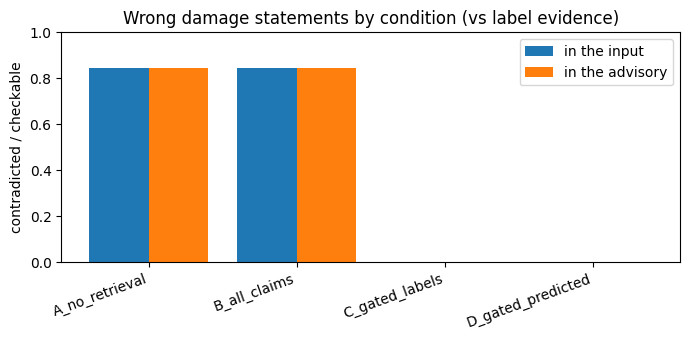

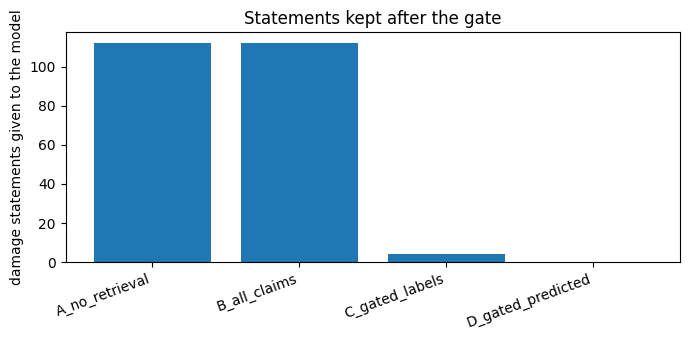

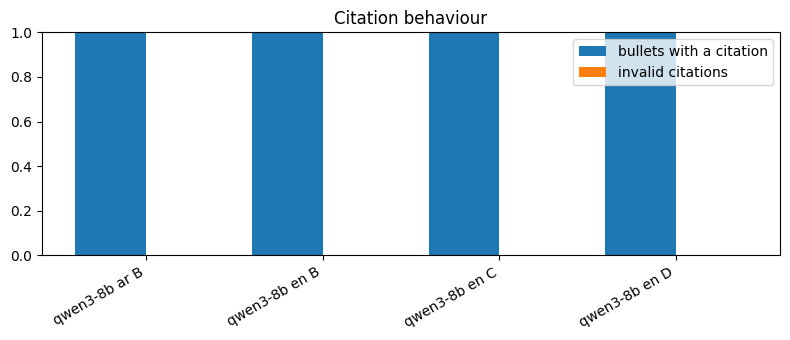

In [16]:
import matplotlib.pyplot as plt


def plot_error_rates(summary, model="qwen3-8b", lang="en"):
    """Bars: damage-statement error rate and input error rate by condition."""
    s = summary[(summary["model"] == model) & (summary["lang"] == lang)].set_index("condition")
    fig, ax = plt.subplots(figsize=(7, 3.5))
    x = np.arange(len(s))
    ax.bar(x - 0.2, s["input_error_rate"].astype(float).fillna(0), 0.4, label="in the input")
    ax.bar(x + 0.2, s["error_rate"].astype(float).fillna(0), 0.4, label="in the advisory")
    ax.set_xticks(x); ax.set_xticklabels(s.index, rotation=20, ha="right")
    ax.set_ylabel("contradicted / checkable"); ax.set_ylim(0, 1); ax.legend()
    ax.set_title("Wrong damage statements by condition (vs label evidence)")
    plt.tight_layout(); plt.savefig(f"{OUT}/plot_error_rates.png", dpi=150); plt.show()


def plot_statements_kept(summary, model="qwen3-8b", lang="en"):
    """Bars: how many damage statements reach the advisory under each condition."""
    s = summary[(summary["model"] == model) & (summary["lang"] == lang)].set_index("condition")
    fig, ax = plt.subplots(figsize=(7, 3.5))
    ax.bar(s.index, s["statements_input"])
    ax.set_ylabel("damage statements given to the model"); ax.set_xticks(range(len(s))); ax.set_xticklabels(s.index, rotation=20, ha="right")
    ax.set_title("Statements kept after the gate")
    plt.tight_layout(); plt.savefig(f"{OUT}/plot_statements_kept.png", dpi=150); plt.show()


def plot_citation_rates(summary):
    """Bars: cited bullet rate and invalid citation rate, per model, language and condition."""
    s = summary[summary["condition"] != "A_no_retrieval"].copy()
    s["label"] = s["model"] + " " + s["lang"] + " " + s["condition"].str[:1]
    fig, ax = plt.subplots(figsize=(8, 3.5))
    x = np.arange(len(s))
    ax.bar(x - 0.2, s["cited_bullet_rate"].astype(float).fillna(0), 0.4, label="bullets with a citation")
    ax.bar(x + 0.2, s["invalid_citation_rate"].astype(float).fillna(0), 0.4, label="invalid citations")
    ax.set_xticks(x); ax.set_xticklabels(s["label"], rotation=30, ha="right"); ax.set_ylim(0, 1); ax.legend()
    ax.set_title("Citation behaviour")
    plt.tight_layout(); plt.savefig(f"{OUT}/plot_citation_rates.png", dpi=150); plt.show()


plot_error_rates(summary)
plot_statements_kept(summary)
plot_citation_rates(summary)

In [20]:
print(FORCE_DEMO, CORPUS, {r.get("corpus") for r in load_runs(RUNS_FILE)})

False guidance {'demo', 'guidance'}


## 9. Human rating sheets

Two sheets are written. Condition names and model names are kept in a separate key file so the rater does not see them.

1. **Passage support** (about 100 bullets, English and Arabic): for each cited bullet, is it supported by the cited passage? Labels: `supported`, `partly`, `not supported`. Skipped for the demo corpus.
2. **Arabic comparison** (one row per tile, two versions shown in random order): faithfulness to the passages (1 to 5), fluency (1 to 5), citation use (1 to 5), and which version is better. Needs an Arabic reader.

Fill the `label` column (sheet 1) and the score columns (sheet 2), save as `*_labelled.csv`, and run the scoring cell at the end.

In [17]:
def make_support_sheet(runs, n=100, seed=SEED):
    """(sheet, key). Cited bullets from conditions with retrieval, sampled across languages and conditions."""
    rows = []
    for r in runs:
        if r.get("error") or not r["passages"]:
            continue
        for i, b in enumerate(parse_output(r["text"])["bullets"]):
            ids = [c for c in b["cites"] if 1 <= c <= len(r["passages"])]
            if ids:
                rows.append({"tile": r["tile"], "model": r["model"], "lang": r["lang"], "condition": r["condition"],
                             "bullet": b["text"], "cited_passages": " || ".join(r["passages"][c - 1]["text"] for c in ids),
                             "passage_ids": " ".join(r["passages"][c - 1]["id"] for c in ids)})
    df = pd.DataFrame(rows)
    if df.empty:
        return df, df
    df = df.sample(n=min(n, len(df)), random_state=seed).reset_index(drop=True)
    df.insert(0, "item_id", [f"s{i:03d}" for i in range(len(df))])
    sheet = df[["item_id", "lang", "bullet", "cited_passages"]].assign(label="", note="")
    key = df[["item_id", "tile", "model", "lang", "condition", "passage_ids"]]
    return sheet, key


def render_advisory(text):
    """Readable advisory for a rating sheet: situation lines, then bullets with their citation tags."""
    p = parse_output(text)
    bullets = [f"- {b['text']} " + " ".join(f"[P{c}]" for c in b["cites"]) for b in p["bullets"]]
    return "\n".join(p["situation"] + ["ADVICE:"] + bullets).strip()


def make_arabic_sheet(runs, condition="B_all_claims", seed=SEED):
    """(sheet, key). Per tile, the Qwen and Falcon Arabic advisories side by side in random order."""
    by = {(r["model"], r["tile"]): r for r in runs if r["lang"] == "ar" and r["condition"] == condition and not r.get("error")}
    rng = random.Random(seed)
    rows, keys = [], []
    for tile in sorted({t for _, t in by}):
        q, f = by.get(("qwen3-8b", tile)), by.get(("falcon-h1-arabic", tile))
        if not q or not f:
            continue
        pair = [("qwen3-8b", q), ("falcon-h1-arabic", f)]
        rng.shuffle(pair)
        rows.append({"tile": tile, "passages": "\n".join(f"[P{i}] {p['text']}" for i, p in enumerate(q["passages"], 1)),
                     "version_1": render_advisory(pair[0][1]["text"]), "version_2": render_advisory(pair[1][1]["text"]),
                     "faithfulness_v1": "", "fluency_v1": "", "citation_use_v1": "",
                     "faithfulness_v2": "", "fluency_v2": "", "citation_use_v2": "", "better": "", "note": ""})
        keys.append({"tile": tile, "model_v1": pair[0][0], "model_v2": pair[1][0]})
    return pd.DataFrame(rows), pd.DataFrame(keys)


sheet_s, key_s = make_support_sheet(runs)
if CORPUS == "guidance" and len(sheet_s):
    sheet_s.to_csv(f"{OUT}/support_sheet.csv", index=False)
    key_s.to_csv(f"{OUT}/support_key.csv", index=False)
    print("support sheet:", len(sheet_s), "bullets")
else:
    print("support sheet skipped (demo corpus or no cited bullets)")
sheet_a, key_a = make_arabic_sheet(runs)
if len(sheet_a):
    sheet_a.to_csv(f"{OUT}/arabic_sheet.csv", index=False)
    key_a.to_csv(f"{OUT}/arabic_key.csv", index=False)
    print("arabic sheet:", len(sheet_a), "tiles")
else:
    print("arabic sheet not written (needs both models on the same tiles)")

support sheet: 100 bullets
arabic sheet not written (needs both models on the same tiles)


In [21]:
import os
import pandas as pd
import ipywidgets as widgets
from IPython.display import display, clear_output


def label_support_buttons(sheet_csv, out_csv):
    """Rate each bullet against its cited passage with buttons. Saves after every click; rerun to continue."""
    sheet = pd.read_csv(sheet_csv, dtype=str).fillna("")
    done = pd.read_csv(out_csv, dtype=str).fillna("") if os.path.exists(out_csv) else sheet.copy()
    todo = [i for i, r in done.iterrows() if not r["label"]]
    out = widgets.Output()
    note = widgets.Text(placeholder="optional note", layout=widgets.Layout(width="360px"))
    buttons = [widgets.Button(description=d, layout=widgets.Layout(width="150px"))
               for d in ("supported", "partly", "not supported")]
    state = {"k": 0}

    def show():
        with out:
            clear_output(wait=True)
            if state["k"] >= len(todo):
                print("all bullets rated, saved to", out_csv)
                return
            i = todo[state["k"]]
            print(f"item {i + 1} of {len(done)}  ({done.at[i, 'lang']})")
            print("BULLET:", done.at[i, "bullet"])
            print("CITED PASSAGE(S):", done.at[i, "cited_passages"])

    def choose(button):
        if state["k"] >= len(todo):
            return
        i = todo[state["k"]]
        done.at[i, "label"] = button.description
        done.at[i, "note"] = note.value
        done.to_csv(out_csv, index=False)
        note.value = ""
        state["k"] += 1
        show()

    for b in buttons:
        b.on_click(choose)
    display(widgets.HBox(buttons + [note]))
    display(out)
    show()
    return done


rated = label_support_buttons(f"{OUT}/support_sheet.csv", f"{OUT}/support_sheet_labelled.csv")

Output()

In [23]:
def score_support(labelled_csv, key_csv):
    """Support rate per language and condition: supported = 1, partly = 0.5, not supported = 0."""
    lab, key = pd.read_csv(labelled_csv, dtype=str).fillna(""), pd.read_csv(key_csv, dtype=str)
    df = lab.merge(key[["item_id", "model", "condition"]], on="item_id")
    df = df[df["label"].str.strip() != ""]
    rows = []
    for (lang, model, cond), g in df.groupby(["lang", "model", "condition"]):
        pts = [{"supported": 1.0, "partly": 0.5}.get(x.strip().lower(), 0.0) for x in g["label"]]
        rows.append({"lang": lang, "model": model, "condition": cond, "rated": len(g),
                     "supported": sum(p == 1.0 for p in pts), "partly": sum(p == 0.5 for p in pts),
                     "support_rate": round(float(np.mean(pts)), 3)})
    return pd.DataFrame(rows)


def score_arabic(labelled_csv, key_csv):
    """Mean faithfulness, fluency and citation score per model, and how often each was preferred."""
    lab, key = pd.read_csv(labelled_csv, dtype=str).fillna(""), pd.read_csv(key_csv, dtype=str)
    df = lab.merge(key, on="tile")
    rows = []
    for _, r in df.iterrows():
        for v in ("1", "2"):
            vals = [r[f"{m}_v{v}"] for m in ("faithfulness", "fluency", "citation_use")]
            if all(x.strip() for x in vals):
                rows.append({"model": r[f"model_v{v}"], "faithfulness": float(vals[0]), "fluency": float(vals[1]),
                             "citation_use": float(vals[2]), "preferred": r["better"].strip() == v})
    t = pd.DataFrame(rows)
    return t.groupby("model").agg(rated=("fluency", "size"), faithfulness=("faithfulness", "mean"), fluency=("fluency", "mean"),
                                  citation_use=("citation_use", "mean"), preferred=("preferred", "sum")).round(2) if len(t) else t


for name, fn, lab, key in (("support", score_support, f"{OUT}/support_sheet_labelled.csv", f"{OUT}/support_key.csv"),
                           ("arabic", score_arabic, f"{OUT}/arabic_sheet_labelled.csv", f"{OUT}/arabic_key.csv")):
    if os.path.exists(lab) and os.path.exists(key):
        print(name); print(fn(lab, key).to_string())
    else:
        print(name, ": not labelled yet")

support
  lang     model          condition  rated  supported  partly  support_rate
0   ar  qwen3-8b       B_all_claims     13         10       3         0.885
1   en  qwen3-8b       B_all_claims     36         35       1         0.986
2   en  qwen3-8b     C_gated_labels     39         38       1         0.987
3   en  qwen3-8b  D_gated_predicted     12         12       0         1.000
arabic : not labelled yet
